<a href="https://colab.research.google.com/github/siva-balaji2007/DL-UnitTest/blob/main/app.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Selected interval: 2006-12-16 17:24:00 to 2006-12-23 16:03:00
Missing values before filling:
 Global_active_power      2
Global_reactive_power    2
Voltage                  2
Global_intensity         2
dtype: int64
Sequence counts: 6940 1000 2000
Epoch 1/8


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


109/109 ━━━━━━━━━━━━━━━━━━━━ 11s 79ms/step - loss: 0.0093 - val_loss: 0.0028
Epoch 2/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 7s 62ms/step - loss: 0.0058 - val_loss: 0.0021
Epoch 3/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - loss: 0.0053 - val_loss: 0.0023
Epoch 4/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 8s 76ms/step - loss: 0.0051 - val_loss: 0.0018
Epoch 5/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - loss: 0.0048 - val_loss: 0.0021
Epoch 6/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step - loss: 0.0048 - val_loss: 0.0019
Epoch 7/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - loss: 0.0045 - val_loss: 0.0017
Epoch 8/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 8s 72ms/step - loss: 0.0044 - val_loss: 0.0015
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step
LSTM: MAE = 0.5409 kW, RMSE = 0.7436 kW
Persistence baseline: MAE = 0.4092 kW, RMSE = 0.7361 kW


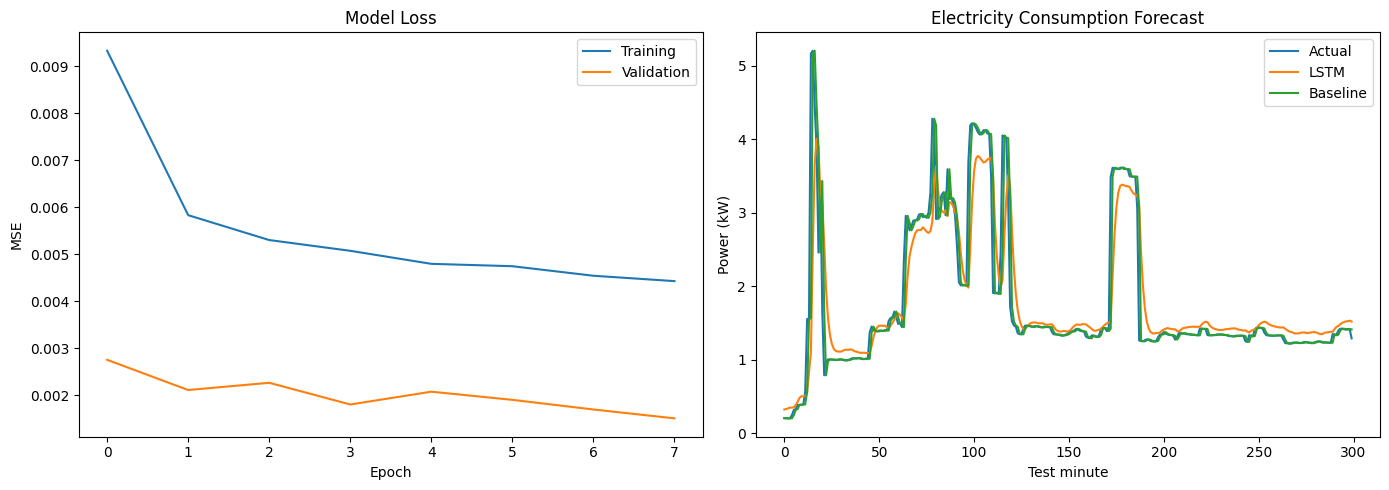

Done! Check the output folder.


In [7]:

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# 1. Find the dataset
os.makedirs("output", exist_ok=True)

if os.path.exists("data/household_power_consumption.txt"):
    file = "data/household_power_consumption.txt"
elif os.path.exists("household_power_consumption.txt"):
    file = "household_power_consumption.txt"
elif os.path.exists("data/household_power_consumption.zip"):
    with zipfile.ZipFile("data/household_power_consumption.zip") as z:
        z.extractall("data")
    file = "data/household_power_consumption.txt"
elif os.path.exists("household_power_consumption.zip"):
    with zipfile.ZipFile("household_power_consumption.zip") as z:
        z.extractall(".")
    file = "household_power_consumption.txt"
else:
    raise FileNotFoundError("Please put the real dataset in the project folder or data folder.")

# 2. Load 10,000 records
df = pd.read_csv(file, sep=";", na_values="?")

df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"], dayfirst=True, errors="coerce"
)
df = df.dropna(subset=["Datetime"]).head(10000).copy()
df = df.set_index("Datetime")

features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity"
]

if len(df) != 10000:
    raise ValueError("The dataset has fewer than 10,000 usable records.")

if not (df.index.to_series().diff().dropna() == pd.Timedelta(minutes=1)).all():
    raise ValueError("The first 10,000 records are not consecutive minutes.")

print("Selected interval:", df.index[0], "to", df.index[-1])
print("Missing values before filling:\n", df[features].isna().sum())

# Fill missing values
df[features] = df[features].interpolate().ffill().bfill()

if df[features].isna().any().any():
    raise ValueError("Missing values remain after filling.")

# 3. Split chronologically: 70% train, 10% validation, 20% test
data = df[features].values
train_end = int(len(data) * 0.7)
val_end = int(len(data) * 0.8)

train = data[:train_end]
val = data[train_end:val_end]
test = data[val_end:]

# Scale using training data only
scaler = MinMaxScaler()
train = scaler.fit_transform(train)
val = scaler.transform(val)
test = scaler.transform(test)

# 4. Create sequences using the previous 60 minutes
def make_sequences(current, context=None):
    if context is not None:
        current = np.vstack([context[-60:], current])

    X, y = [], []
    for i in range(60, len(current)):
        X.append(current[i-60:i])
        y.append(current[i, 0])

    return np.array(X), np.array(y)

X_train, y_train = make_sequences(train)
X_val, y_val = make_sequences(val, train)
X_test, y_test = make_sequences(test, val)

print("Sequence counts:", len(X_train), len(X_val), len(X_test))

# 5. Build and train the LSTM
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(60, 4)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=64
)

model.save("output/lstm_power_model.keras")

# 6. Convert predictions back to kW
pred_scaled = model.predict(X_test).ravel()

def to_kw(values):
    full = np.zeros((len(values), 4))
    full[:, 0] = values
    return scaler.inverse_transform(full)[:, 0]

actual = to_kw(y_test)
predicted = to_kw(pred_scaled)

# Predict next minute using the previous actual value
baseline = np.r_[val[-1, 0], test[:-1, 0]]
baseline = to_kw(baseline)

# 7. Evaluate both models
for name, prediction in [
    ("LSTM", predicted),
    ("Persistence baseline", baseline)
]:
    mae = mean_absolute_error(actual, prediction)
    rmse = np.sqrt(mean_squared_error(actual, prediction))
    print(f"{name}: MAE = {mae:.4f} kW, RMSE = {rmse:.4f} kW")

# Save predictions with timestamps
results = pd.DataFrame({
    "Datetime": df.index[val_end:],
    "Actual_kW": actual,
    "LSTM_Predicted_kW": predicted,
    "Baseline_kW": baseline
})
results.to_csv("output/predictions.csv", index=False)

# 8. Plot training loss and predictions
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(history.history["loss"], label="Training")
ax[0].plot(history.history["val_loss"], label="Validation")
ax[0].set_title("Model Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("MSE")
ax[0].legend()

ax[1].plot(actual[:300], label="Actual")
ax[1].plot(predicted[:300], label="LSTM")
ax[1].plot(baseline[:300], label="Baseline")
ax[1].set_title("Electricity Consumption Forecast")
ax[1].set_xlabel("Test minute")
ax[1].set_ylabel("Power (kW)")
ax[1].legend()

plt.tight_layout()
plt.savefig("output/evaluation.png")
plt.show()

print("Done! Check the output folder.")
